========== U-NET DATALOADER TEST ==========
Training samples: 7870
Validation samples: 1680
Testing samples: 1710
Image batch shape: torch.Size([4, 1, 224, 224])
Mask batch shape: torch.Size([4, 1, 224, 224])
Image range: 0.0 0.9960784316062927
Mask range: 0.0 1.0
U-Net DataLoader test completed.


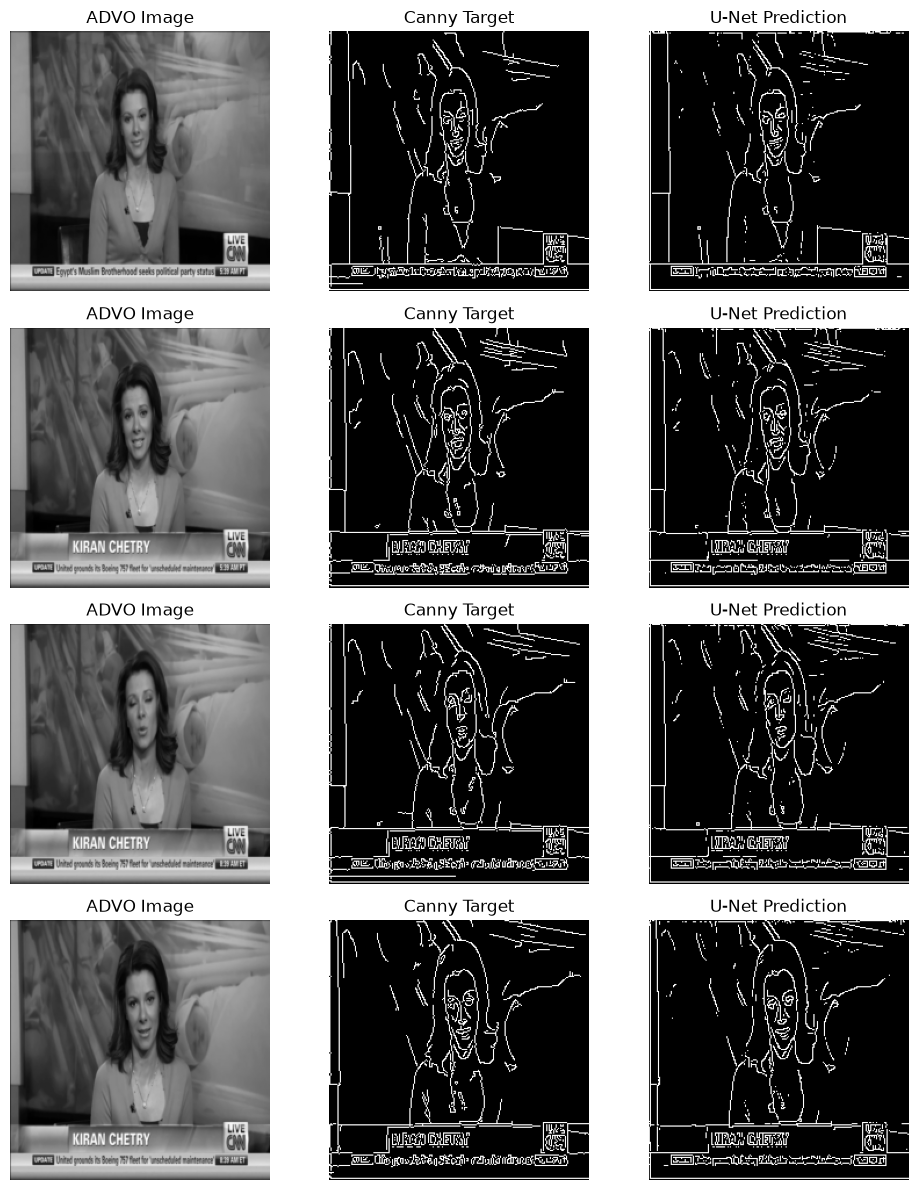

In [4]:
import torch
import matplotlib.pyplot as plt

from unet_model import UNet
from unet_dataloader import test_loader

device = torch.device("cpu")

model = UNet(in_channels=1, out_channels=1).to(device)

model.load_state_dict(
    torch.load(
        "/home/rag/Code/unet_trained.pth",
        map_location=device
    )
)

model.eval()

images, masks = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images)
    predictions = torch.sigmoid(outputs)
    predictions = (predictions > 0.5).float()

# Display first four examples
fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for i in range(4):

    axes[i, 0].imshow(images[i][0], cmap="gray")
    axes[i, 0].set_title("ADVO Image")

    axes[i, 1].imshow(masks[i][0], cmap="gray")
    axes[i, 1].set_title("Canny Target")

    axes[i, 2].imshow(predictions[i][0], cmap="gray")
    axes[i, 2].set_title("U-Net Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("/home/rag/Code/unet_predictions.png")
plt.show()